In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC


In [2]:
data_path = Path("Bankruptcy100by100noNA.txt")
output_dir = Path(".")
# Match archived gamma=2, C=200; include C=1 for comparison.
model_specs = [(2, 1), (2, 200)]
data = np.genfromtxt(data_path, delimiter="\t", names=True)
x = np.column_stack([data["x24"], data["x3"]])
y = data["T2"].astype(int)
x_mean = x.mean(axis=0)
x_std = x.std(axis=0, ddof=1)
x_scaled = (x - x_mean) / x_std
assert np.isfinite(x).all() and set(y) == {-1, 1}
print(f"Observations: {len(y)}; solvent: {(y == 1).sum()}; insolvent: {(y == -1).sum()}")


Observations: 100; solvent: 50; insolvent: 50


gamma=2, C=1: training error=0.22; support vectors=80
gamma=2, C=200: training error=0.10; support vectors=63


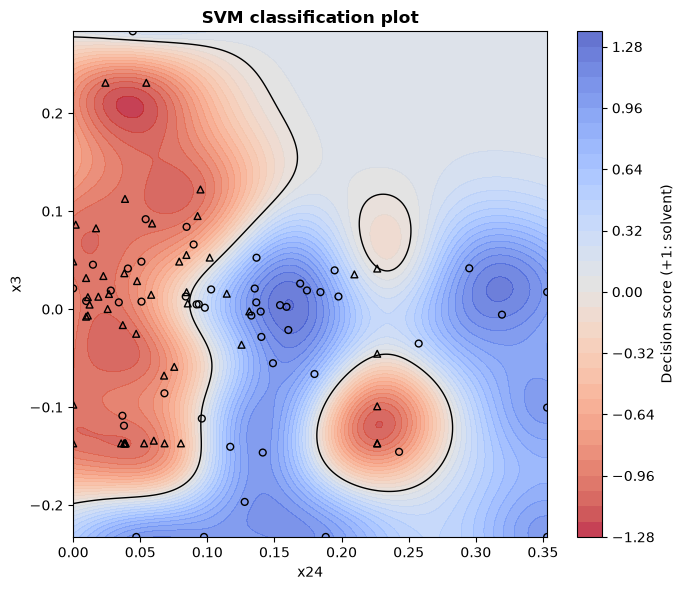

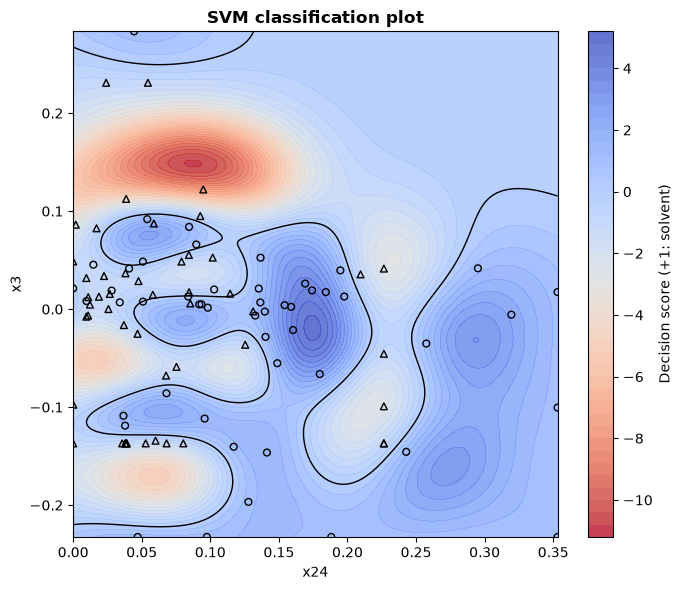

In [3]:
xx, yy = np.meshgrid(np.linspace(x[:, 0].min(), x[:, 0].max(), 250), np.linspace(x[:, 1].min(), x[:, 1].max(), 250))
# Grid columns follow the training matrix: x24, x3.
grid = (np.column_stack([xx.ravel(), yy.ravel()]) - x_mean) / x_std
results = []
for gamma, capacity in model_specs:
    model = SVC(C=capacity, kernel="rbf", gamma=gamma)
    model.fit(x_scaled, y)
    error = np.mean(model.predict(x_scaled) != y)
    score = model.decision_function(grid).reshape(xx.shape)
    results.append((gamma, capacity, error, len(model.support_)))
    plt.figure(figsize=(7, 6))
    contour = plt.contourf(xx, yy, score, levels=40, cmap="coolwarm_r", alpha=0.8)
    if score.min() < 0 < score.max():
        plt.contour(xx, yy, score, levels=[0], colors="black", linewidths=1)
    plt.scatter(x[y == 1, 0], x[y == 1, 1], marker="o", facecolors="none", edgecolors="black", s=24)
    plt.scatter(x[y == -1, 0], x[y == -1, 1], marker="^", facecolors="none", edgecolors="black", s=24)
    plt.xlabel("x24")
    plt.ylabel("x3")
    plt.title("SVM classification plot", fontweight="bold")
    plt.colorbar(contour, label="Decision score (+1: solvent)")
    plt.tight_layout()
    plt.savefig(output_dir / f"20260915 svm_gamma_{gamma:g}_c_{capacity}.png", dpi=300, transparent=True)
    plt.show()
    plt.close()
    print(f"gamma={gamma:g}, C={capacity}: training error={error:.2f}; support vectors={len(model.support_)}")
np.savetxt(output_dir / "20260915 model_results.csv", results, delimiter=",", header="gamma,C,training_error,support_vectors", comments="")
